In [1]:
import os
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

import tensorflow as tf
from keras.layers import Input
from keras.models import Model, Sequential
from keras.layers import Reshape, Dense, Dropout, Flatten, Input, LeakyReLU
from keras.datasets import mnist
from keras.optimizers import Adam

2026-07-04 21:16:28.704862: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1783192588.865946    4496 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1783192588.912255    4496 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-07-04 21:16:29.328861: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# MNIST data
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# X_train = X_train.astype(np.float32) / 255
X_train = (X_train.astype(np.float32) - 127.5) / 127.5
X_train = X_train.reshape(60000, 784)

In [3]:
BATCH_SIZE = 128

In [4]:
dataset = tf.data.Dataset.from_tensor_slices(X_train).shuffle(60000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

I0000 00:00:1783192598.986612    4496 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 7082 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1070, pci bus id: 0000:01:00.0, compute capability: 6.1


In [5]:
randomDim = 100

In [6]:
# Generator Network
generator = Sequential()
generator.add(Input(shape=(randomDim,)))
generator.add(Dense(256))
generator.add(LeakyReLU(0.2))
generator.add(Dense(512))
generator.add(LeakyReLU(0.2))
generator.add(Dense(1024))
generator.add(LeakyReLU(0.2))
generator.add(Dense(784, activation='tanh'))

In [7]:
# Discriminator Network
discriminator = Sequential()
discriminator.add(Input(shape=(784,)))
discriminator.add(Dense(1024))
discriminator.add(LeakyReLU(0.2))
discriminator.add(Dropout(0.3))
discriminator.add(Dense(512))
discriminator.add(LeakyReLU(0.2))
discriminator.add(Dropout(0.3))
discriminator.add(Dense(256))
discriminator.add(LeakyReLU(0.2))
discriminator.add(Dropout(0.3))
discriminator.add(Dense(1, activation='sigmoid'))

In [8]:
# # Optimizer
# opt_gan = Adam(learning_rate=0.0002)
# opt_dis = Adam(learning_rate=0.0002)

In [9]:
# # Combined network
# ganInput = Input(shape=(randomDim,))
# x = generator(ganInput)
# ganOutput = discriminator(x)
# gan = Model(inputs=ganInput, outputs=ganOutput)
# gan.compile(loss='binary_crossentropy', optimizer=opt_gan)

In [10]:
# Train

In [15]:
def plotGeneratedImages(epoch, examples=100, dim=(10, 10), figsize=(10, 10)):
    noise = np.random.normal(0, 1, size=[examples, randomDim])
    generatedImages = generator.predict(noise)
    generatedImages = generatedImages.reshape(examples, 28, 28)

    plt.figure(figsize=figsize)
    for i in range(generatedImages.shape[0]):
        plt.subplot(dim[0], dim[1], i+1)
        plt.imshow(generatedImages[i], interpolation='nearest', cmap='gray')
        plt.axis('off')
    plt.tight_layout()
    out_dir = './generated image/'
    os.makedirs(out_dir, exist_ok=True)
    out = os.path.join(out_dir, 'generated_image_epoch_%d.png' % epoch)
    plt.savefig(out)
    plt.close()

In [16]:
generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002)

cross_entropy = tf.keras.losses.BinaryCrossentropy()

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output) * 0.9, real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    total_loss = real_loss + fake_loss
    return total_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

In [17]:
@tf.function
def train_step(images):
    batch_size = tf.shape(images)[0]
    noise_d = tf.random.normal([batch_size, randomDim])
    
    with tf.GradientTape() as disc_tape:
        generated_images = generator(noise_d, training=True)
        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)
        disc_loss = discriminator_loss(real_output, fake_output)
    
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    
    noise_g = tf.random.normal([batch_size, randomDim])
    with tf.GradientTape() as gen_tape:
        generated_images = generator(noise_g, training=True)
        fake_output = discriminator(generated_images, training=True)
        gen_loss = generator_loss(fake_output)
        
    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    
    return disc_loss, gen_loss

In [18]:
epochs = 200
dLosses = []
gLosses = []

for e in range(1, epochs + 1):
    epoch_d_loss = []
    epoch_g_loss = []

    print('-' * 10, 'Epoch %d' % e, '-' * 10)
    for image_batch in tqdm(dataset):
        d_loss, g_loss = train_step(image_batch)

        epoch_d_loss.append(d_loss)
        epoch_g_loss.append(g_loss)
    
    avg_d_loss = np.mean(epoch_d_loss)
    avg_g_loss = np.mean(epoch_g_loss)
    
    dLosses.append(avg_d_loss)
    gLosses.append(avg_g_loss)

    print(f"Epoch {e}, Discriminator Loss: {avg_d_loss}, Generator Loss: {avg_g_loss}")

    if e == 1 or e % 10 == 0:
        plotGeneratedImages(e)

---------- Epoch 1 ----------


100%|████████████████████████████████████████| 469/469 [00:05<00:00, 89.07it/s]

Epoch 1, Discriminator Loss: 1.1220424175262451, Generator Loss: 2.8789072036743164
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


---------- Epoch 2 ----------


100%|███████████████████████████████████████| 469/469 [00:02<00:00, 192.07it/s]


...

Epoch 198, Discriminator Loss: 1.260666847229004, Generator Loss: 1.077219009399414
---------- Epoch 199 ----------


100%|███████████████████████████████████████| 469/469 [00:02<00:00, 176.30it/s]


Epoch 199, Discriminator Loss: 1.2678803205490112, Generator Loss: 1.0559279918670654
---------- Epoch 200 ----------


100%|███████████████████████████████████████| 469/469 [00:02<00:00, 177.64it/s]


Epoch 200, Discriminator Loss: 1.258010983467102, Generator Loss: 1.0774595737457275
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


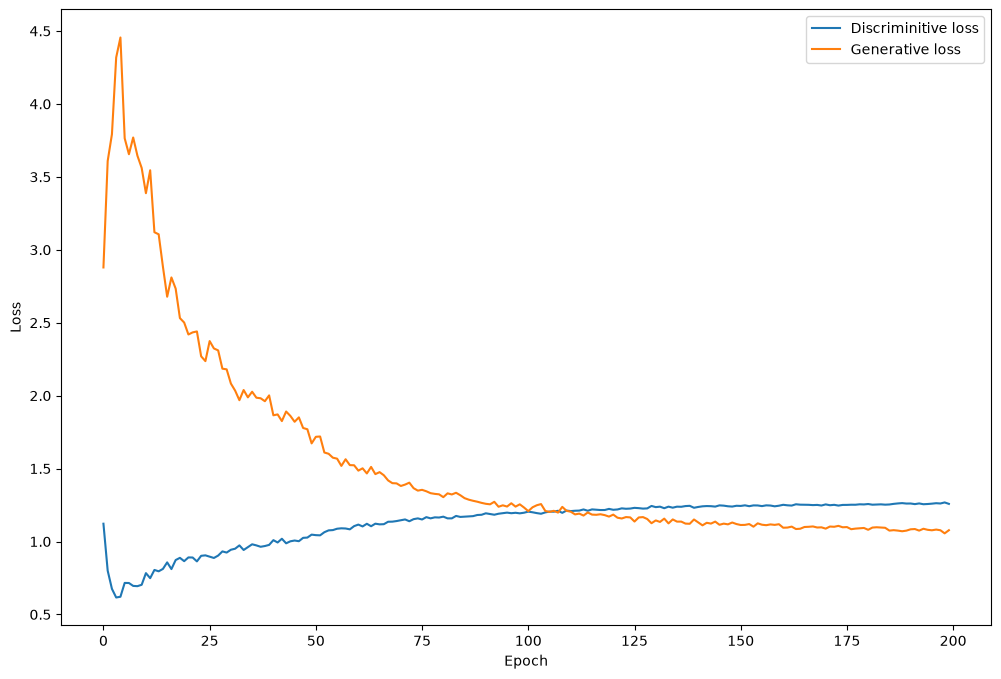

In [19]:
plt.figure(figsize=(12, 8))
plt.plot(dLosses, label='Discriminitive loss')
plt.plot(gLosses, label='Generative loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


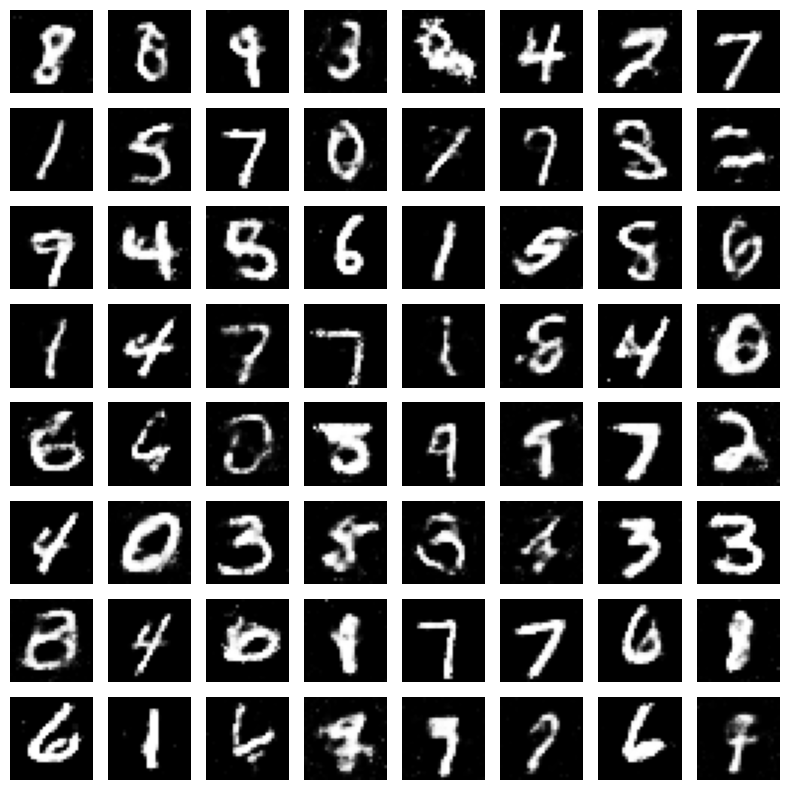

In [20]:
num_images = 64

noise = tf.random.normal(shape=[num_images, 100])

generated_images = generator.predict(noise)

generated_images = generated_images.reshape(num_images, 28, 28)

plt.figure(figsize=(8, 8))
for i in range(num_images):
    plt.subplot(8, 8, i+1)
    plt.imshow(generated_images[i], cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()